# Plant Disease Detection

This project looks at a photo of a leaf and tells you which disease the plant has.

**The 7 steps**

| Step | What we do |
|---|---|
| 1 | Load the dataset |
| 2 | EDA - look at the data |
| 3 | Feature engineering - turn photos into numbers |
| 4 | Model training - train 6 models |
| 5 | Cross validation - check the models properly |
| 6 | Classification report - compare them and save the best one |
| 7 | Make `app.py` - the website |

**Dataset:** PlantVillage (*New Plant Diseases Dataset*) from Kaggle.
It has photos of healthy and sick leaves, sorted into one folder per disease.

## Step 0: Install and import the libraries

In [ ]:
!pip -q install xgboost lightgbm scikit-learn pillow torch streamlit

These are the normal Python tools we need.

In [2]:
import os
import glob
import time
import pickle
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

warnings.filterwarnings("ignore")      # hide messages that are not important

print("Basic tools ready")

Basic tools ready


These are the machine learning tools.

In [3]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

print("Machine learning tools ready")

Machine learning tools ready


These are for the CNN (the neural network).

In [4]:
import torch
import torch.nn as nn

# this makes the results the same every time we run the notebook
np.random.seed(0)
torch.manual_seed(0)

print("Deep learning tools ready")

Deep learning tools ready


# Step 1: Dataset Loading

The dataset is one big folder, with **a smaller folder inside it for each disease**:

```
PlantVillage/
    Apple___Apple_scab/       0000.jpg  0001.jpg  ...
    Apple___healthy/          0000.jpg  0001.jpg  ...
    Tomato___Late_blight/     0000.jpg  0001.jpg  ...
```

The **name of the folder is the answer** for every photo inside it.

### If you are using Google Colab

Put the dataset in your Google Drive, then run this:

```python
from google.colab import drive
drive.mount('/content/drive')
DATA_DIR = "/content/drive/MyDrive/PlantVillage"
```

Or upload a zip file and unzip it:

```python
!unzip -q PlantVillage.zip -d /content/
DATA_DIR = "/content/PlantVillage"
```

In [5]:
DATA_DIR = "data/PlantVillage"      # <--- change this line if your folder is somewhere else

print("Looking inside:", DATA_DIR)

Looking inside: data/PlantVillage


### Find the names of the diseases

Every folder name is one disease. We put the names into a list called `classes`.
The **position** in the list is the number the computer uses: 0, 1, 2, and so on.

In [6]:
classes = []

for folder_name in sorted(os.listdir(DATA_DIR)):
    full_path = os.path.join(DATA_DIR, folder_name)
    if os.path.isdir(full_path):
        classes.append(folder_name)

print("Number of diseases (classes):", len(classes))

Number of diseases (classes): 38


In [7]:
# show every class and how many photos it has
for number, name in enumerate(classes):
    n_photos = len(os.listdir(os.path.join(DATA_DIR, name)))
    print(number, "-", name, "-", n_photos, "photos")

0 - Apple___Apple_scab - 250 photos
1 - Apple___Black_rot - 250 photos
2 - Apple___Cedar_apple_rust - 250 photos
3 - Apple___healthy - 250 photos
4 - Blueberry___healthy - 250 photos
5 - Cherry_(including_sour)___Powdery_mildew - 250 photos
6 - Cherry_(including_sour)___healthy - 250 photos
7 - Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot - 250 photos
8 - Corn_(maize)___Common_rust_ - 250 photos
9 - Corn_(maize)___Northern_Leaf_Blight - 250 photos
10 - Corn_(maize)___healthy - 250 photos
11 - Grape___Black_rot - 250 photos
12 - Grape___Esca_(Black_Measles) - 250 photos
13 - Grape___Leaf_blight_(Isariopsis_Leaf_Spot) - 250 photos
14 - Grape___healthy - 250 photos
15 - Orange___Haunglongbing_(Citrus_greening) - 250 photos
16 - Peach___Bacterial_spot - 250 photos
17 - Peach___healthy - 250 photos
18 - Pepper,_bell___Bacterial_spot - 250 photos
19 - Pepper,_bell___healthy - 250 photos
20 - Potato___Early_blight - 250 photos
21 - Potato___Late_blight - 250 photos
22 - Potato___healthy

### Two settings

* `IMG_SIZE` - every photo is made **64 x 64** pixels, so they all have the same size.
* `MAX_PER_CLASS` - take only 250 photos from each disease, so the classes stay **equal**
  and the notebook finishes quickly.

> Why 64 and not 224? Small photos are fast. The whole notebook then runs in a few minutes on a
> normal laptop. If you have a GPU you can change it to 224.

In [8]:
IMG_SIZE = 64
MAX_PER_CLASS = 250

### Read the photos

We open every photo, make it 64 x 64, and put it in a list.
We also remember the answer (the class number) for each photo.

In [9]:
images = []      # the photos
labels = []      # the answer for each photo

start_time = time.time()

for class_number, class_name in enumerate(classes):
    folder = os.path.join(DATA_DIR, class_name)
    photo_files = sorted(glob.glob(folder + "/*"))
    photo_files = photo_files[:MAX_PER_CLASS]

    for file_path in photo_files:
        photo = Image.open(file_path)
        photo = photo.convert("RGB")                   # make sure it has 3 colours
        photo = photo.resize((IMG_SIZE, IMG_SIZE))     # make it 64 x 64

        images.append(np.array(photo))
        labels.append(class_number)

print("Finished in", round(time.time() - start_time), "seconds")

Finished in 8 seconds


Now we turn the two lists into numpy arrays, which the machine learning tools understand.

In [10]:
images = np.array(images)
labels = np.array(labels)

print("images:", images.shape)
print("   ", len(images), "photos, each", IMG_SIZE, "x", IMG_SIZE, "with 3 colours")
print("labels:", labels.shape)
print("    the first 10 answers:", labels[:10])

images: (9500, 64, 64, 3)
    9500 photos, each 64 x 64 with 3 colours
labels: (9500,)
    the first 10 answers: [0 0 0 0 0 0 0 0 0 0]


# Step 2: EDA (Exploratory Data Analysis)

EDA just means **looking at the data before we build anything**.

We want to answer 4 questions:

1. Does every disease have the same number of photos?
2. How many plants are there, and how many leaves are healthy?
3. What do the photos look like?
4. Are sick leaves a different colour from healthy leaves?

### 2.1 Does every disease have the same number of photos?

In [11]:
photos_per_class = []

for class_number in range(len(classes)):
    how_many = np.sum(labels == class_number)
    photos_per_class.append(how_many)

print("Total photos  :", sum(photos_per_class))
print("Smallest class:", min(photos_per_class), "photos")
print("Biggest class :", max(photos_per_class), "photos")

Total photos  : 9500
Smallest class: 250 photos
Biggest class : 250 photos


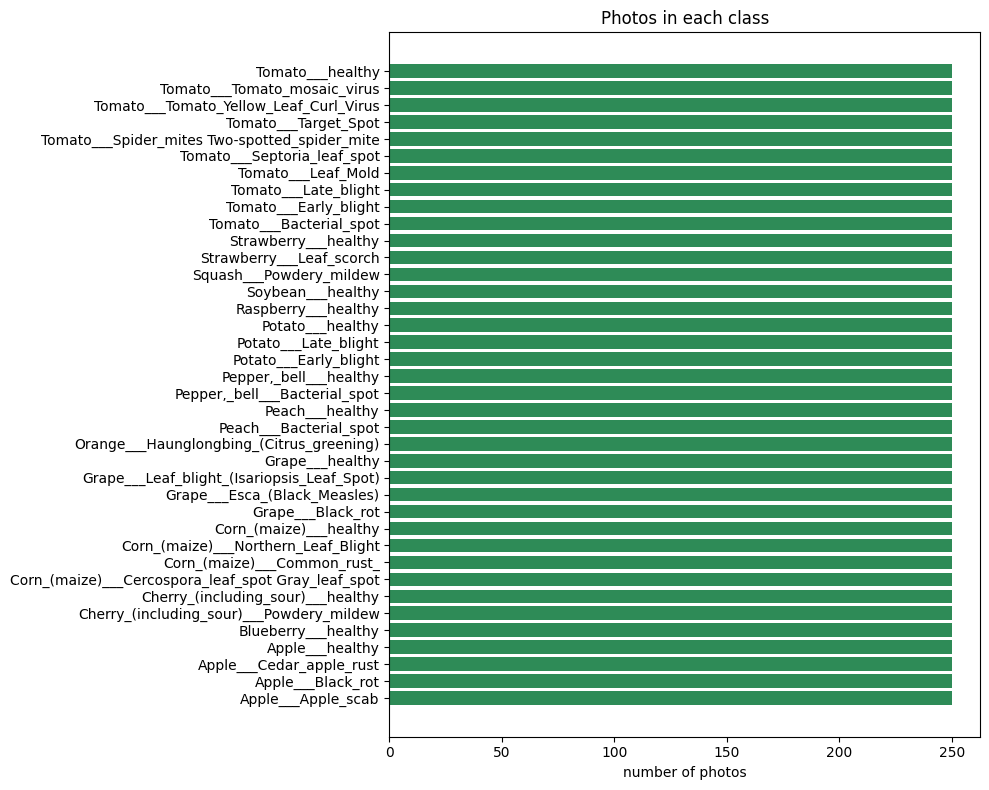

In [12]:
plt.figure(figsize=(10, 8))
plt.barh(classes, photos_per_class, color="seagreen")
plt.xlabel("number of photos")
plt.title("Photos in each class")
plt.tight_layout()
plt.show()

All the bars are the same length, so the dataset is **balanced**.

That is good. If one disease had many more photos, the model would just learn to guess that one.

### 2.2 How many plants, and how many are healthy?

The class names look like `Tomato___Late_blight`.
The part before `___` is the **plant**, the part after it is the **disease**.

In [13]:
plant_names = []
healthy_count = 0
diseased_count = 0

for class_number, class_name in enumerate(classes):
    plant = class_name.split("___")[0]
    plant_names.append(plant)

    if "healthy" in class_name.lower():
        healthy_count = healthy_count + photos_per_class[class_number]
    else:
        diseased_count = diseased_count + photos_per_class[class_number]

print("Different plants:", len(set(plant_names)))
print(sorted(set(plant_names)))
print()
print("Healthy leaves :", healthy_count)
print("Diseased leaves:", diseased_count)

Different plants: 14
['Apple', 'Blueberry', 'Cherry_(including_sour)', 'Corn_(maize)', 'Grape', 'Orange', 'Peach', 'Pepper,_bell', 'Potato', 'Raspberry', 'Soybean', 'Squash', 'Strawberry', 'Tomato']

Healthy leaves : 3000
Diseased leaves: 6500


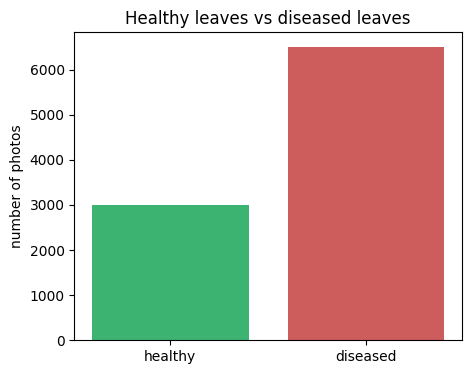

In [14]:
plt.figure(figsize=(5, 4))
plt.bar(["healthy", "diseased"], [healthy_count, diseased_count],
        color=["mediumseagreen", "indianred"])
plt.ylabel("number of photos")
plt.title("Healthy leaves vs diseased leaves")
plt.show()

### 2.3 What do the photos look like?

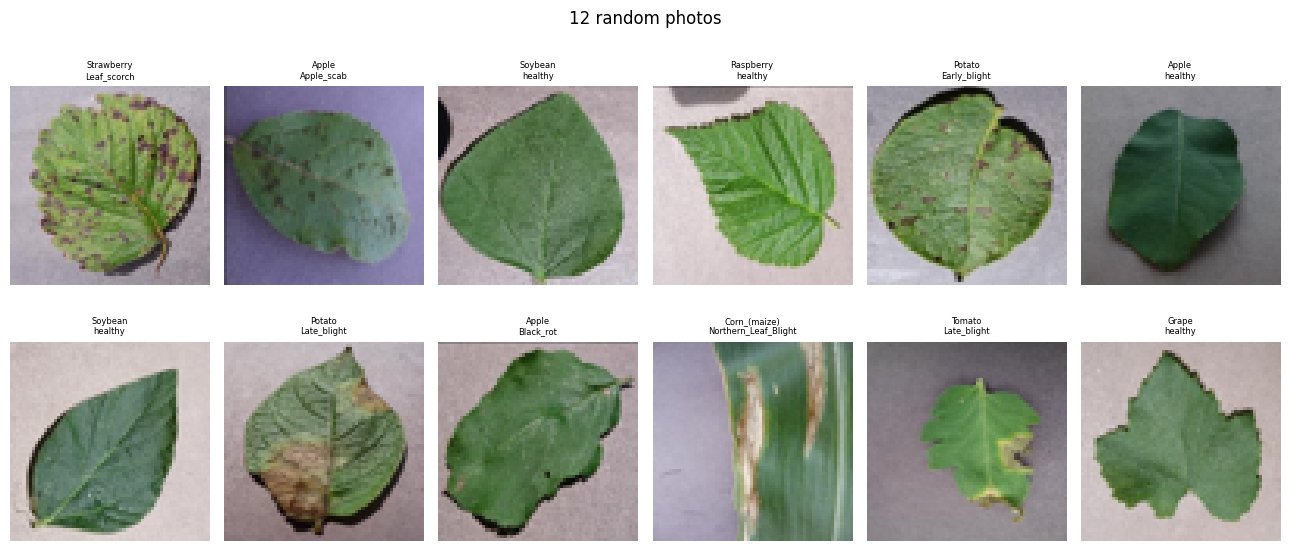

In [15]:
# pick 12 photos at random and show them
random_numbers = np.random.choice(len(images), 12, replace=False)

plt.figure(figsize=(13, 6))
for position, photo_number in enumerate(random_numbers):
    plt.subplot(2, 6, position + 1)
    plt.imshow(images[photo_number])
    plt.axis("off")
    plt.title(classes[labels[photo_number]].replace("___", "\n"), fontsize=6)

plt.suptitle("12 random photos")
plt.tight_layout()
plt.show()

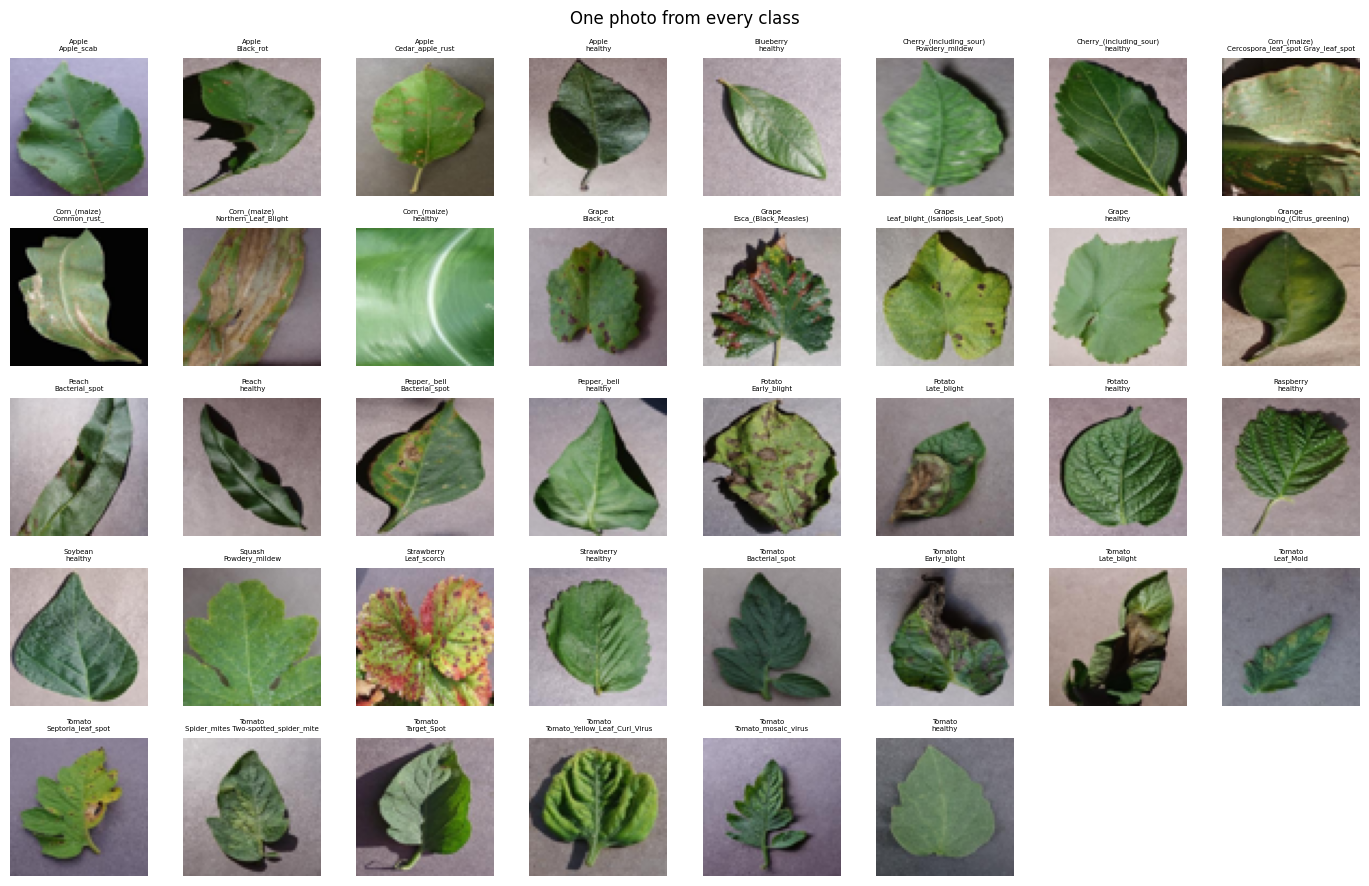

In [16]:
# show one photo from every class
plt.figure(figsize=(14, 9))

for class_number in range(len(classes)):
    first_photo = np.where(labels == class_number)[0][0]
    plt.subplot(5, 8, class_number + 1)
    plt.imshow(images[first_photo])
    plt.axis("off")
    plt.title(classes[class_number].replace("___", "\n"), fontsize=5)

plt.suptitle("One photo from every class")
plt.tight_layout()
plt.show()

### 2.4 Are sick leaves a different colour?

This is the most important question in the whole project.
If sick leaves have a different colour, then **colour is a good clue** and simple models will work.

In [17]:
# mark which photos are healthy
is_healthy = []
for class_number in labels:
    is_healthy.append("healthy" in classes[class_number].lower())

is_healthy = np.array(is_healthy)

# the average amount of red, green and blue in each group
healthy_colour = images[is_healthy].mean(axis=(0, 1, 2))
diseased_colour = images[~is_healthy].mean(axis=(0, 1, 2))

print("Average colour of HEALTHY leaves  (red, green, blue):", healthy_colour.round(1))
print("Average colour of DISEASED leaves (red, green, blue):", diseased_colour.round(1))

Average colour of HEALTHY leaves  (red, green, blue): [129.6 139.9 121.5]
Average colour of DISEASED leaves (red, green, blue): [118.5 122.7 103.5]


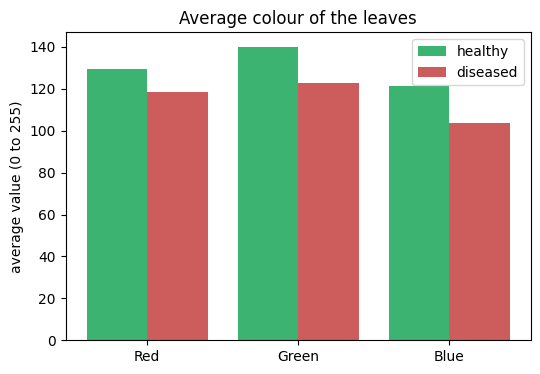

In [18]:
positions = np.array([0, 1, 2])

plt.figure(figsize=(6, 4))
plt.bar(positions - 0.2, healthy_colour, width=0.4, label="healthy", color="mediumseagreen")
plt.bar(positions + 0.2, diseased_colour, width=0.4, label="diseased", color="indianred")
plt.xticks(positions, ["Red", "Green", "Blue"])
plt.ylabel("average value (0 to 255)")
plt.title("Average colour of the leaves")
plt.legend()
plt.show()

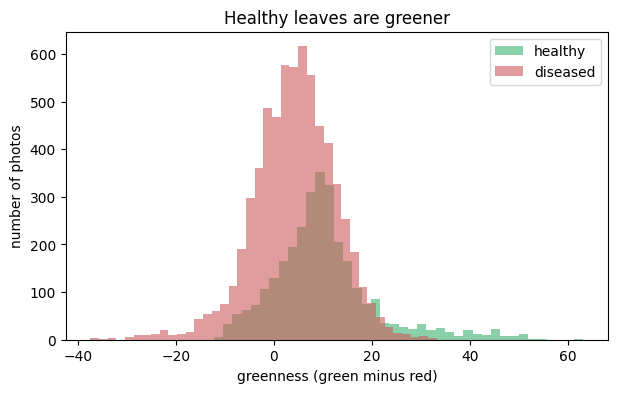

In [19]:
# "greenness" = how much more green than red a photo has
average_green = images[:, :, :, 1].mean(axis=(1, 2))
average_red = images[:, :, :, 0].mean(axis=(1, 2))
greenness = average_green - average_red

plt.figure(figsize=(7, 4))
plt.hist(greenness[is_healthy], bins=40, alpha=0.6, label="healthy", color="mediumseagreen")
plt.hist(greenness[~is_healthy], bins=40, alpha=0.6, label="diseased", color="indianred")
plt.xlabel("greenness (green minus red)")
plt.ylabel("number of photos")
plt.title("Healthy leaves are greener")
plt.legend()
plt.show()

**What the EDA told us**

* Every class has the same number of photos - the dataset is balanced.
* There are many different plants, both healthy and sick.
* Healthy leaves are clearly **greener**. Sick leaves have more brown and yellow.

So colour is a very useful clue. We use that in the next step.

# Step 3: Feature Engineering

Models like XGBoost cannot read a photo. They need a **row of numbers**.

One 64 x 64 colour photo has 64 x 64 x 3 = **12,288** numbers. That is far too many, and very slow.

So we make our own **54 numbers** that describe each photo:

| What | How many | What it tells us |
|---|---|---|
| Colour histogram | 48 | how much of each shade of red, green and blue is in the leaf |
| Average colour | 3 | the overall colour of the leaf |
| Colour spread | 3 | how **spotty** the leaf is |

The colour spread is the clever one: a sick leaf has **spots**, so its colour changes a lot across
the photo. A healthy leaf is one even colour.

We also **normalize** the photo by dividing by 255, so every number is between 0 and 1.

### The function that makes the 54 numbers

In [20]:
BINS = 16      # 16 groups for each colour  ->  16 x 3 = 48 histogram numbers


def make_features(picture):
    """Takes one photo (64 x 64 x 3, values from 0 to 1) and gives back 54 numbers."""
    total_pixels = IMG_SIZE * IMG_SIZE

    # 1. the colour histogram: how many pixels fall into each shade
    histogram = []
    for colour in range(3):                   # 0 = red, 1 = green, 2 = blue
        counts, _ = np.histogram(picture[:, :, colour], bins=BINS, range=(0, 1))
        histogram.append(counts / total_pixels)

    # 2. the average colour (3 numbers)
    average_colour = picture.mean(axis=(0, 1))

    # 3. how much the colour changes = spottiness (3 numbers)
    colour_spread = picture.std(axis=(0, 1))

    # join everything into one long row
    return np.concatenate(histogram + [average_colour, colour_spread])

### Try it on one photo first

In [21]:
first_photo = images[0] / 255.0             # normalize to 0 - 1
example = make_features(first_photo)

print("The photo has  ", images[0].size, "numbers")
print("Our features have", len(example), "numbers")
print()
print("Average colour of this leaf:", example[48:51].round(3))
print("Colour spread of this leaf :", example[51:54].round(3))

The photo has   12288 numbers
Our features have 54 numbers

Average colour of this leaf: [0.434 0.511 0.47 ]
Colour spread of this leaf : [0.173 0.136 0.223]


### Now do it for every photo

In [22]:
X = []
for photo in images:
    X.append(make_features(photo / 255.0))

X = np.array(X)
y = labels                        # y is the answer we want the models to learn

print("X (the features):", X.shape)
print("y (the answers) :", y.shape)

X (the features): (9500, 54)
y (the answers) : (9500,)


### Split into training photos and testing photos

We train the models on **80%** of the photos and hide **20%** from them.
Later we test on the hidden photos, which the models have never seen.
That tells us if they really learned, or only memorised.

In [23]:
X_train, X_test, y_train, y_test, images_train, images_test = train_test_split(
    X, y, images, test_size=0.2, random_state=42, stratify=y)

print("Training photos:", len(X_train))
print("Testing photos :", len(X_test))

Training photos: 7600
Testing photos : 1900


# Step 4: Model Training

We train **6 different models** and later see which one is best.

| Model | What it does |
|---|---|
| Logistic Regression | the simplest model, draws straight lines between the classes |
| Random Forest | many decision trees vote together |
| XGBoost | builds trees one by one, each fixing the last one's mistakes |
| LightGBM | the same idea as XGBoost, but faster |
| Voting Ensemble | **ensemble method** - Random Forest, XGBoost and LightGBM vote together |
| CNN | a neural network that looks at the pixels |

### 4.1 Make the four simple models

In [24]:
def make_the_models():
    """Gives back a fresh, untrained copy of our four models."""
    return {
        "Logistic Regression": make_pipeline(StandardScaler(),
                                             LogisticRegression(max_iter=2000)),
        "Random Forest": RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=-1),
        "XGBoost": XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                                 tree_method="hist", random_state=0),
        # verbose=-1 just means "do not print training messages"
        "LightGBM": LGBMClassifier(n_estimators=300, random_state=0, n_jobs=-1, verbose=-1),
    }


models = make_the_models()
print("Models so far:", list(models))

Models so far: ['Logistic Regression', 'Random Forest', 'XGBoost', 'LightGBM']


### 4.2 Make the ensemble

The ensemble asks three models and goes with the answer they agree on most.

We give it a **fresh copy** of the three models. If we gave it the same objects we train above,
the saved file would end up containing every model twice, and be twice as big.

In [25]:
fresh_copies = make_the_models()

models["Voting Ensemble"] = VotingClassifier(
    estimators=[("rf", fresh_copies["Random Forest"]),
                ("xgb", fresh_copies["XGBoost"]),
                ("lgbm", fresh_copies["LightGBM"])],
    voting="soft",           # "soft" means they vote with probabilities, not just yes or no
    n_jobs=-1)

print("All 5 models:", list(models))

All 5 models: ['Logistic Regression', 'Random Forest', 'XGBoost', 'LightGBM', 'Voting Ensemble']


### 4.3 Train them

`.fit()` is the command that trains a model.

In [26]:
for name in models:
    start_time = time.time()
    models[name].fit(X_train, y_train)
    print(name, "- trained in", round(time.time() - start_time), "seconds")

Logistic Regression - trained in 1 seconds


Random Forest - trained in 1 seconds


XGBoost - trained in 19 seconds


LightGBM - trained in 7 seconds


Voting Ensemble - trained in 37 seconds


### 4.4 Build the CNN (Convolutional Neural Network)

A CNN looks at the **pixels** instead of our 54 numbers. It finds the useful patterns by itself.

| Layer | What it does |
|---|---|
| `Conv2d` | slides small filters over the photo to find patterns like edges and spots |
| `MaxPool2d` | makes the photo half as big, keeping only the strongest signals |
| `Flatten` | turns the photo into one long row of numbers |
| `Linear` (Dense) | a normal layer that makes the final decision |
| `Dropout` | switches off some neurons while training, so the model does not just memorise |

*(This is written with PyTorch. In Keras it is the same layers:
`Conv2D / MaxPooling2D / Flatten / Dense / Dropout / Dense`.)*

In [27]:
cnn = nn.Sequential(
    nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),     # 64x64 -> 32x32
    nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 32x32 -> 16x16
    nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 16x16 -> 8x8
    nn.Flatten(),
    nn.Linear(64 * 8 * 8, 128), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(128, len(classes)),
)

print(cnn)

Sequential(
  (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (7): ReLU()
  (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (9): Flatten(start_dim=1, end_dim=-1)
  (10): Linear(in_features=4096, out_features=128, bias=True)
  (11): ReLU()
  (12): Dropout(p=0.3, inplace=False)
  (13): Linear(in_features=128, out_features=38, bias=True)
)


PyTorch wants the photos in a slightly different shape: `(photo, colour, height, width)`
instead of `(photo, height, width, colour)`. We divide by 255 here too.

In [28]:
def photos_for_pytorch(photo_array):
    numbers = photo_array.astype(np.float32) / 255.0      # make the values 0 to 1
    numbers = numbers.transpose(0, 3, 1, 2)               # move the colour to the front
    return torch.tensor(numbers)


train_photos = photos_for_pytorch(images_train)
train_answers = torch.tensor(y_train, dtype=torch.long)

test_photos = photos_for_pytorch(images_test)
test_answers = torch.tensor(y_test, dtype=torch.long)

print("Training photos for the CNN:", tuple(train_photos.shape))

Training photos for the CNN: (7600, 3, 64, 64)


### 4.5 Train the CNN

One **epoch** means the CNN has seen every training photo once. We do 12 epochs.

Inside each epoch we go through the photos in small groups of 64, called **batches**.

In [29]:
EPOCHS = 12
BATCH_SIZE = 64

optimizer = torch.optim.Adam(cnn.parameters(), lr=0.001)
loss_function = nn.CrossEntropyLoss()

train_accuracy_list = []
test_accuracy_list = []
train_loss_list = []
test_loss_list = []

start_time = time.time()

for epoch in range(EPOCHS):
    cnn.train()
    correct = 0
    total_loss = 0.0

    # go through the training photos in batches, in a random order
    order = torch.randperm(len(train_photos))

    for start in range(0, len(order), BATCH_SIZE):
        rows = order[start:start + BATCH_SIZE]
        batch_photos = train_photos[rows]
        batch_answers = train_answers[rows]

        optimizer.zero_grad()                           # forget the last step
        guess = cnn(batch_photos)                       # the CNN makes a guess
        loss = loss_function(guess, batch_answers)      # how wrong was it?
        loss.backward()                                 # work out how to improve
        optimizer.step()                                # improve

        total_loss = total_loss + loss.item() * len(rows)
        correct = correct + (guess.argmax(1) == batch_answers).sum().item()

    train_accuracy = correct / len(train_photos)
    train_loss = total_loss / len(train_photos)

    # now check it on the hidden test photos
    cnn.eval()
    with torch.no_grad():
        guess = cnn(test_photos)
        test_loss = loss_function(guess, test_answers).item()
        test_accuracy = (guess.argmax(1) == test_answers).float().mean().item()

    train_accuracy_list.append(train_accuracy)
    train_loss_list.append(train_loss)
    test_accuracy_list.append(test_accuracy)
    test_loss_list.append(test_loss)

    print(f"epoch {epoch + 1:2d}/{EPOCHS}   "
          f"train accuracy {train_accuracy:.3f}   train loss {train_loss:.3f}   "
          f"test accuracy {test_accuracy:.3f}   test loss {test_loss:.3f}")

print("\nCNN trained in", round(time.time() - start_time), "seconds")

epoch  1/12   train accuracy 0.091   train loss 3.363   test accuracy 0.263   test loss 2.647


epoch  2/12   train accuracy 0.301   train loss 2.437   test accuracy 0.400   test loss 2.074


epoch  3/12   train accuracy 0.397   train loss 2.038   test accuracy 0.514   test loss 1.682


epoch  4/12   train accuracy 0.448   train loss 1.821   test accuracy 0.524   test loss 1.594


epoch  5/12   train accuracy 0.488   train loss 1.660   test accuracy 0.561   test loss 1.466


...

epoch  8/12   train accuracy 0.596   train loss 1.282   test accuracy 0.683   test loss 1.063


epoch  9/12   train accuracy 0.609   train loss 1.236   test accuracy 0.672   test loss 1.080


epoch 10/12   train accuracy 0.635   train loss 1.140   test accuracy 0.698   test loss 0.998


epoch 11/12   train accuracy 0.651   train loss 1.084   test accuracy 0.707   test loss 0.927


epoch 12/12   train accuracy 0.667   train loss 1.029   test accuracy 0.719   test loss 0.949

CNN trained in 48 seconds


### 4.6 The CNN accuracy and loss graphs

Accuracy should go **up**, loss should go **down**.

If the training line keeps improving but the test line stops, the model is **overfitting** -
it is memorising the training photos instead of learning.

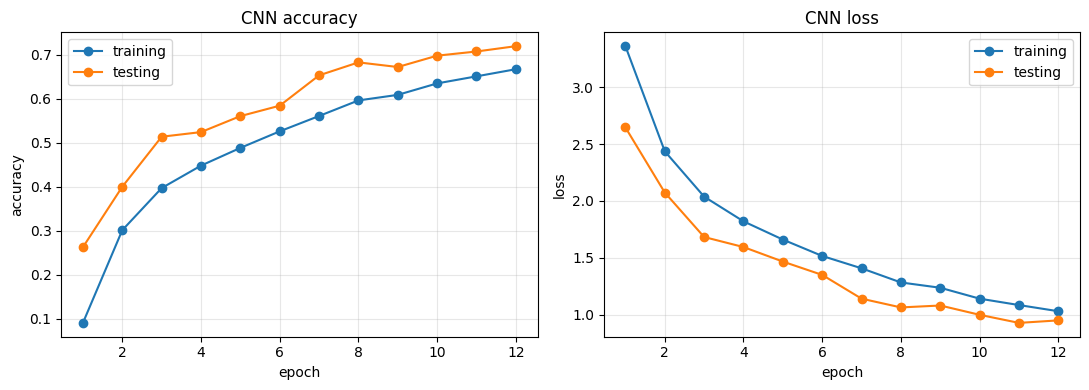

In [30]:
epoch_numbers = range(1, EPOCHS + 1)

plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
plt.plot(epoch_numbers, train_accuracy_list, marker="o", label="training")
plt.plot(epoch_numbers, test_accuracy_list, marker="o", label="testing")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.title("CNN accuracy")
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epoch_numbers, train_loss_list, marker="o", label="training")
plt.plot(epoch_numbers, test_loss_list, marker="o", label="testing")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("CNN loss")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Step 5: Cross Validation

Testing a model only once can be lucky. **Cross validation** is fairer:

1. Cut the training photos into 3 equal parts
2. Train on 2 parts and test on the part left out
3. Do that 3 times, so every part gets tested once
4. Take the average of the 3 scores

If the 3 scores are close together, the model is **stable** and we can trust it.

*(The CNN is not included here. Cross validation would mean training the neural network 3 more
times, which takes far too long. We use its score on the hidden test photos instead.)*

In [31]:
cv_average = {}
cv_spread = {}

for name in models:
    start_time = time.time()
    three_scores = cross_val_score(models[name], X_train, y_train, cv=3, n_jobs=-1)

    cv_average[name] = three_scores.mean()
    cv_spread[name] = three_scores.std()

    print(f"{name:22s} scores = {three_scores.round(3)}   "
          f"average = {three_scores.mean():.3f}   [{round(time.time() - start_time)}s]")

Logistic Regression    scores = [0.61  0.608 0.616]   average = 0.611   [5s]


Random Forest          scores = [0.803 0.786 0.797]   average = 0.795   [8s]


XGBoost                scores = [0.815 0.803 0.811]   average = 0.810   [29s]


LightGBM               scores = [0.826 0.809 0.825]   average = 0.820   [25s]


Voting Ensemble        scores = [0.828 0.815 0.825]   average = 0.822   [43s]


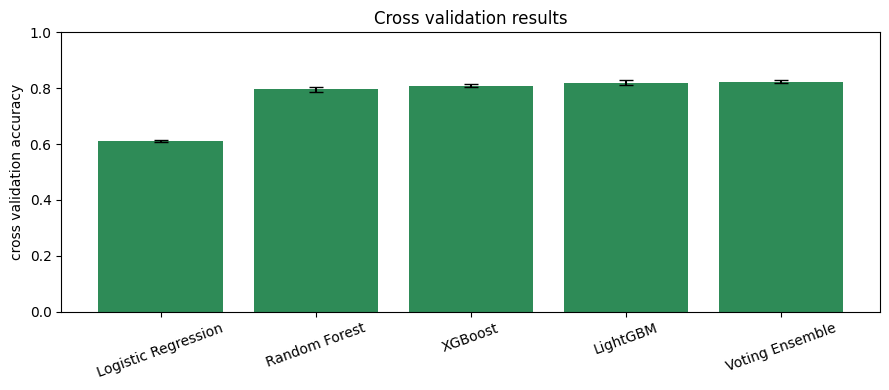

In [32]:
plt.figure(figsize=(9, 4))
plt.bar(list(cv_average), list(cv_average.values()),
        yerr=list(cv_spread.values()), capsize=5, color="seagreen")
plt.ylabel("cross validation accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.title("Cross validation results")
plt.tight_layout()
plt.show()

# Step 6: Classification Report, and save the best model

A **classification report** gives 4 numbers for every disease:

| Word | What it means |
|---|---|
| precision | when the model says "Late blight", how often is it right? |
| recall | out of all the real Late blight leaves, how many did it find? |
| f1-score | one number that balances precision and recall |
| support | how many test photos of that disease there were |

We compare the models using the **macro average f1-score**. That is the f1-score averaged over all
the diseases, so every disease counts the same. It is fairer than plain accuracy.

### 6.1 Ask every model to guess the hidden test photos

In [33]:
guesses = {}

for name in models:
    guesses[name] = models[name].predict(X_test)

# the CNN needs the photos, not the 54 numbers
cnn.eval()
with torch.no_grad():
    guesses["CNN"] = cnn(test_photos).argmax(1).numpy()

print("All 6 models have made their guesses.")

All 6 models have made their guesses.


### 6.2 Print the classification report of every model

In [34]:
for name in guesses:
    print("=" * 70)
    print(name)
    print("=" * 70)
    print(classification_report(y_test, guesses[name], target_names=classes, zero_division=0))

Logistic Regression
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.55      0.64      0.59        50
                                 Apple___Black_rot       0.79      0.68      0.73        50
                          Apple___Cedar_apple_rust       0.64      0.32      0.43        50
                                   Apple___healthy       0.68      0.56      0.62        50
                               Blueberry___healthy       0.76      0.76      0.76        50
          Cherry_(including_sour)___Powdery_mildew       0.37      0.32      0.34        50
                 Cherry_(including_sour)___healthy       0.89      0.82      0.85        50
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.52      0.34      0.41        50
                       Corn_(maize)___Common_rust_       1.00      1.00      1.00        50
               Corn_(maize)___Northern_Leaf_Blight       0.

### 6.3 Put the important numbers into one table

In [35]:
rows = []

for name in guesses:
    report = classification_report(y_test, guesses[name], target_names=classes,
                                   zero_division=0, output_dict=True)
    rows.append({
        "model": name,
        "accuracy": report["accuracy"],
        "precision": report["macro avg"]["precision"],
        "recall": report["macro avg"]["recall"],
        "macro_f1": report["macro avg"]["f1-score"],
    })

summary = pd.DataFrame(rows)
summary = summary.sort_values("macro_f1", ascending=False).reset_index(drop=True)
summary.round(3)

,model,accuracy,precision,recall,macro_f1
0,Voting Ensemble,0.876,0.877,0.876,0.875
1,LightGBM,0.876,0.878,0.876,0.875
2,XGBoost,0.872,0.876,0.872,0.872
3,Random Forest,0.854,0.857,0.854,0.852
4,CNN,0.719,0.734,0.719,0.714
5,Logistic Regression,0.634,0.633,0.634,0.627


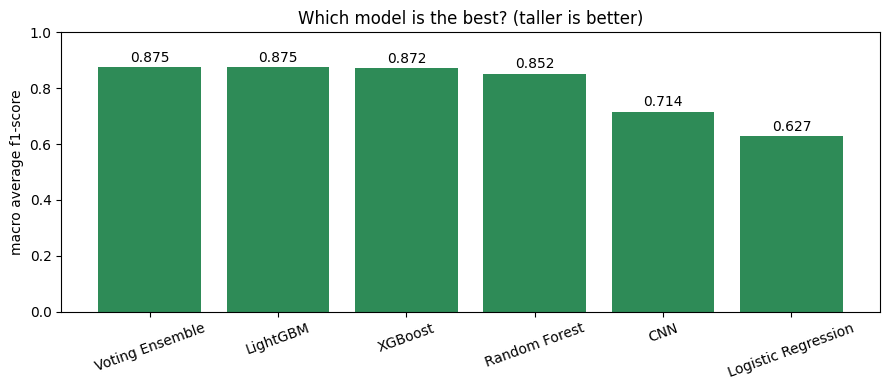

In [36]:
plt.figure(figsize=(9, 4))
plt.bar(summary["model"], summary["macro_f1"], color="seagreen")
plt.ylabel("macro average f1-score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.title("Which model is the best? (taller is better)")

for position in range(len(summary)):
    score = summary["macro_f1"][position]
    plt.text(position, score + 0.02, round(score, 3), ha="center")

plt.tight_layout()
plt.show()

### 6.4 The winner

The table is sorted best-first, so the best model is simply the first row.

In [37]:
best_name = summary["model"][0]
best_model = models[best_name]

print("THE BEST MODEL IS:", best_name)
print("   accuracy      :", round(summary["accuracy"][0], 4))
print("   macro f1-score:", round(summary["macro_f1"][0], 4))

THE BEST MODEL IS: Voting Ensemble
   accuracy      : 0.8758
   macro f1-score: 0.8747


### 6.5 The confusion matrix of the best model

This shows which diseases the model mixes up.
A bright line down the middle means the model is almost always right.
Bright squares anywhere else are the mistakes.

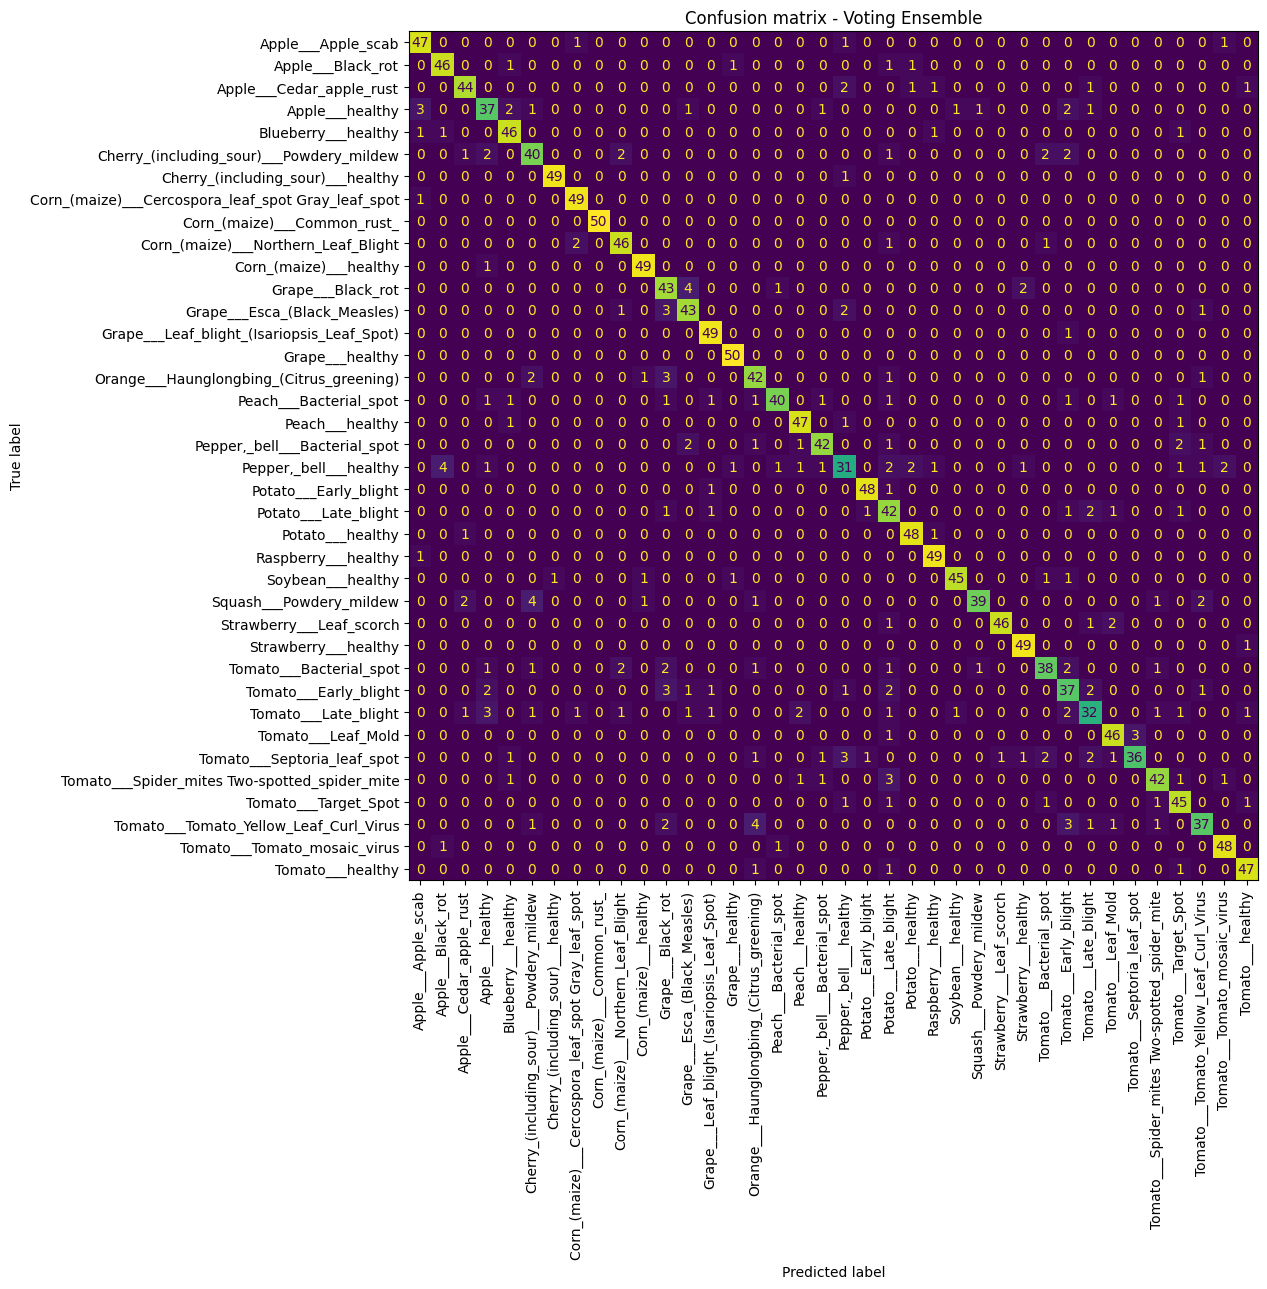

In [38]:
figure, axis = plt.subplots(figsize=(13, 13))

ConfusionMatrixDisplay.from_predictions(y_test, guesses[best_name],
                                        display_labels=classes, xticks_rotation=90,
                                        colorbar=False, ax=axis)

plt.title("Confusion matrix - " + best_name)
plt.tight_layout()
plt.show()

### 6.6 Save the best model

We save the model **together with** the class names and the photo settings, so that the app knows
exactly how to prepare a photo that a user uploads.

In [39]:
saved = {
    "model": best_model,
    "classes": classes,
    "img_size": IMG_SIZE,
    "bins": BINS,
    "name": best_name,
    "test_accuracy": float(summary["accuracy"][0]),
}

with open("plant_disease_model.pkl", "wb") as f:
    pickle.dump(saved, f)

file_size = os.path.getsize("plant_disease_model.pkl") / 1e6

print("Saved plant_disease_model.pkl")
print("   model:", best_name)
print("   size :", round(file_size, 1), "MB")

Saved plant_disease_model.pkl
   model: Voting Ensemble
   size : 163.6 MB


### 6.7 Check that the saved file really works

We load the file back from the disk, the way a different program would, and use it on 10 photos.

In [40]:
with open("plant_disease_model.pkl", "rb") as f:
    loaded = pickle.load(f)

print("Loaded model:", loaded["name"], "with", len(loaded["classes"]), "classes")

Loaded model: Voting Ensemble with 38 classes


In [41]:
def predict_one_photo(photo_image):
    """Takes a photo, gives back the disease name and how sure the model is."""
    photo = photo_image.convert("RGB").resize((loaded["img_size"], loaded["img_size"]))
    picture = np.array(photo, dtype=np.float32) / 255.0

    features = make_features(picture)
    probabilities = loaded["model"].predict_proba([features])[0]

    best = int(np.argmax(probabilities))
    return loaded["classes"][best], probabilities[best]

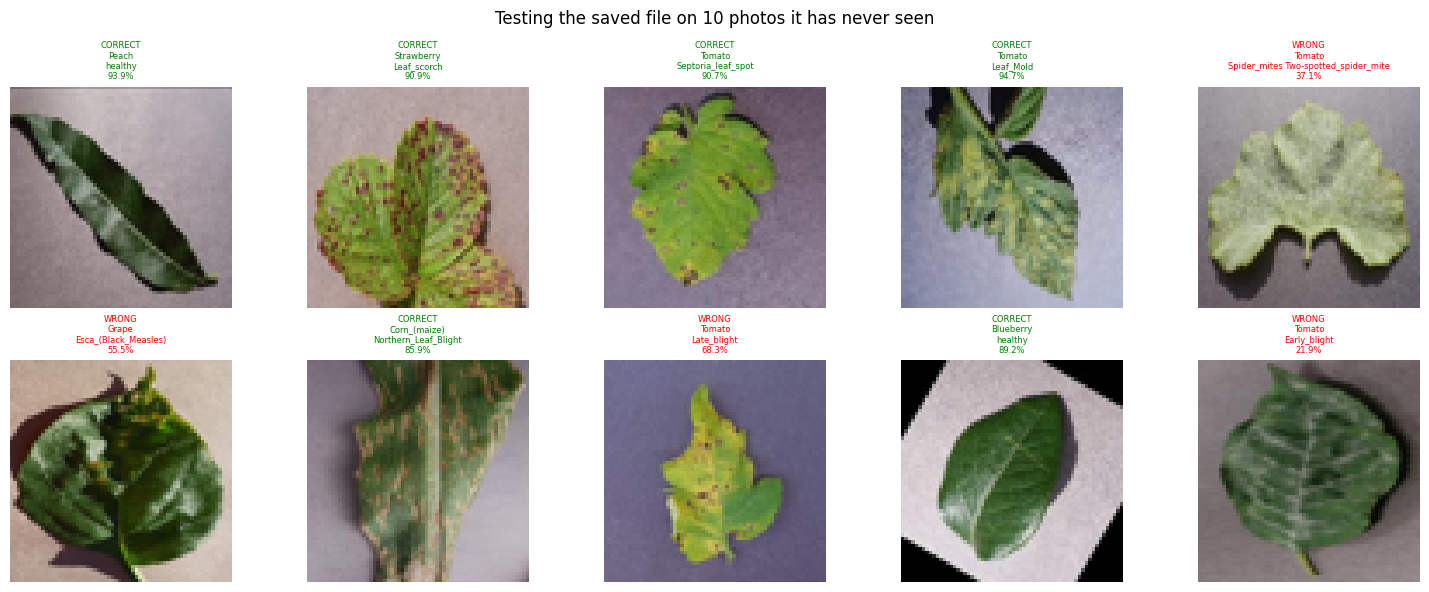

In [42]:
# try it on 10 of the hidden test photos
some_photos = np.random.choice(len(images_test), 10, replace=False)

plt.figure(figsize=(15, 6))

for position, photo_number in enumerate(some_photos):
    photo = Image.fromarray(images_test[photo_number])
    guess, how_sure = predict_one_photo(photo)

    right_answer = classes[y_test[photo_number]]
    is_correct = (guess == right_answer)

    plt.subplot(2, 5, position + 1)
    plt.imshow(images_test[photo_number])
    plt.axis("off")
    plt.title(("CORRECT" if is_correct else "WRONG") + "\n" +
              guess.replace("___", "\n") + "\n" + str(round(how_sure * 100, 1)) + "%",
              fontsize=6, color="green" if is_correct else "red")

plt.suptitle("Testing the saved file on 10 photos it has never seen")
plt.tight_layout()
plt.show()

# Step 7: Make `app.py` (the website)

The cell below creates the file `app.py`. That file is the whole website:

1. the user uploads a photo of a leaf
2. the app prepares it in **exactly the same way** as Step 3
3. it loads `plant_disease_model.pkl`
4. it shows the disease, how sure it is, and what to do about it

To run it on your computer:

```
streamlit run app.py
```

`app.py` and `plant_disease_model.pkl` must be in the **same folder**.
Those two files are everything the website needs.

In [43]:
%%writefile app.py
# app.py - the Plant Disease Detection website
# Run it with:   streamlit run app.py

import pickle
import warnings
import numpy as np
import streamlit as st
from PIL import Image

warnings.filterwarnings("ignore")

st.set_page_config(page_title="Plant Disease Detection", page_icon="\U0001F33F")


# ---------- 1. load the model we saved in the notebook ----------
@st.cache_resource
def load_model():
    with open("plant_disease_model.pkl", "rb") as f:
        return pickle.load(f)


saved = load_model()
IMG_SIZE = saved["img_size"]
BINS = saved["bins"]


# ---------- 2. the same feature engineering as the notebook ----------
def make_features(picture):
    total_pixels = IMG_SIZE * IMG_SIZE

    histogram = []
    for colour in range(3):
        counts, _ = np.histogram(picture[:, :, colour], bins=BINS, range=(0, 1))
        histogram.append(counts / total_pixels)

    average_colour = picture.mean(axis=(0, 1))
    colour_spread = picture.std(axis=(0, 1))

    return np.concatenate(histogram + [average_colour, colour_spread])


# ---------- 3. treatment suggestions ----------
TIPS = {
    "scab": "Rake up fallen leaves, prune the tree for airflow, spray a fungicide at bud break.",
    "blight": "Remove the infected leaves, do not water the leaves, use a copper based fungicide.",
    "spot": "Prune the affected leaves, give the plants more space, avoid overhead watering.",
    "rust": "Clear away infected leaves, rotate the crop next season, spray a sulphur fungicide.",
    "mildew": "Lower the humidity, space the plants further apart, spray a sulphur solution.",
    "mold": "Improve ventilation, lower the humidity, remove the affected leaves.",
    "virus": "There is no cure - remove the plant and control insects like whiteflies and aphids.",
    "mite": "Wash the leaves with water, then use insecticidal soap or neem oil.",
    "scorch": "Water deeply and regularly, mulch the soil, avoid too much fertiliser.",
    "measles": "Prune the infected wood in dry weather and seal the pruning wounds.",
    "rot": "Remove infected fruit and leaves, improve drainage, spray fungicide early in the season.",
    "haunglongbing": "Remove the infected tree and control the psyllid insect that spreads it.",
}


def get_tip(disease_name):
    for word in TIPS:
        if word in disease_name.lower():
            return TIPS[word]
    return "Keep the leaves dry, remove the damaged leaves and check the plant again in a few days."


# ---------- 4. the web page ----------
st.title("\U0001F33F Plant Disease Detection")
st.write("Upload a photo of a leaf and this app will tell you if the plant is sick.")
st.caption(f"Model: {saved['name']}  |  accuracy: {saved['test_accuracy'] * 100:.1f}%"
           f"  |  {len(saved['classes'])} plant diseases")

uploaded_file = st.file_uploader("Choose a leaf photo", type=["jpg", "jpeg", "png"])

if uploaded_file is None:
    st.info("Please upload a leaf photo to start.")
else:
    # show the photo the user uploaded
    image = Image.open(uploaded_file)
    st.image(image, caption="Your leaf", width=320)

    # prepare the photo exactly like the training photos
    photo = image.convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    picture = np.array(photo, dtype=np.float32) / 255.0
    features = make_features(picture)

    # ask the model
    probabilities = saved["model"].predict_proba([features])[0]
    best = int(np.argmax(probabilities))
    full_name = saved["classes"][best]
    confidence = probabilities[best] * 100

    # the names look like "Tomato___Late_blight"
    plant_name, _, disease_name = full_name.partition("___")
    plant_name = plant_name.replace("_", " ").strip()
    disease_name = disease_name.replace("_", " ").strip()

    # show the result
    st.subheader("Result")
    if "healthy" in full_name.lower():
        st.success(f"This {plant_name} leaf is HEALTHY \u2705")
    else:
        st.error(f"This {plant_name} leaf is DISEASED \u26A0\ufe0f")
        st.write(f"**Disease found:** {disease_name}")
        st.info(f"**What to do:** {get_tip(full_name)}")

    st.write(f"**Confidence:** {confidence:.1f}%")
    st.progress(min(int(confidence), 100))

    with st.expander("Show the top 5 guesses"):
        top5 = np.argsort(probabilities)[::-1][:5]
        for i in top5:
            name = saved["classes"][i].replace("___", " - ").replace("_", " ")
            st.write(f"{name} - {probabilities[i] * 100:.1f}%")

Overwriting app.py


### The `requirements.txt` file

This lists the libraries `app.py` needs, and the exact versions we used here.

Anyone can then install everything with one command:

```
pip install -r requirements.txt
```

You also need this file if you put the app online with **Streamlit Community Cloud** -
it reads `requirements.txt` to set up the server.

*(`torch` is not in the list. The CNN was not the best model, so `app.py` does not need it.)*

In [44]:
%%writefile requirements.txt
streamlit==1.64.0
numpy==2.4.2
pillow==12.2.0
scikit-learn==1.8.0
xgboost==3.2.0
lightgbm==4.6.0

Overwriting requirements.txt


### Run the website inside Google Colab (optional)

Colab cannot show a normal website, so we make a tunnel out to the internet.
Run the cell, open the link it prints, and use the IP address it prints as the password.

In [ ]:
!npm install -q localtunnel
!curl -s https://loca.lt/mytunnelpassword          # this is the password
!streamlit run app.py &>/content/log.txt & npx localtunnel --port 8501

### Download the two files (Google Colab only)

In [ ]:
from google.colab import files
files.download("plant_disease_model.pkl")
files.download("app.py")

# Conclusion

* We loaded a dataset of leaf photos sorted into folders by disease.
* The **EDA** showed the dataset is balanced and that healthy leaves are **greener**.
* **Feature engineering** turned each photo into 54 numbers about colour.
* We trained **6 models** and checked them with **cross validation**.
* We compared their **classification reports** and saved the best one.
* `app.py` is a website that uses the saved model to detect plant diseases.

**How to make it better**

* use more photos from each class (increase `MAX_PER_CLASS`)
* use bigger photos, 224 x 224, if you have a GPU
* train the CNN for more epochs
* use transfer learning: start from a model like MobileNet that already knows about images